In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Movimiento browniano

Una partícula inmersa en un líquido experimenta fricción y
fluctuaciones producidas por las colisiones moleculares.
Para una partícula libre, la ecuación de Langevin es

$$
m\frac{d^2x}{dt^2}
=
-\gamma\frac{dx}{dt}+\xi(t),
$$

donde $m$ es la masa, $\gamma$ es el coeficiente de fricción
y $\xi(t)$ es la fuerza fluctuante.

## Propiedades del ruido térmico

La fuerza fluctuante tiene media cero:

$$
\langle\xi(t)\rangle=0.
$$

Esto significa que las fluctuaciones no tienen una dirección
preferida en promedio.

Para un líquido en equilibrio térmico, la correlación es

$$
\langle\xi(t)\xi(t')\rangle
=
2\gamma k_BT\,\delta(t-t').
$$

La delta de Dirac es una distribución matemática, definida
por su acción dentro de una integral:

$$
\int_{-\infty}^{\infty}
\delta(t-t')f(t')\,dt'=f(t).
$$

La correlación del ruido blanco se concentra en tiempos
coincidentes y se anula para tiempos distintos. El ruido
blanco se interpreta mediante sus integrales temporales.

## Formulación mediante un proceso de Wiener

Definimos la velocidad:

$$
v=\frac{dx}{dt}.
$$

El sistema se escribe formalmente como

$$
\begin{aligned}
\frac{dx}{dt}&=v,\\
m\frac{dv}{dt}&=-\gamma v+\xi(t).
\end{aligned}
$$

Mediante un proceso de Wiener, su formulación precisa es

$$
\begin{aligned}
dx_t&=v_t\,dt,\\
m\,dv_t&=-\gamma v_t\,dt
+\sqrt{2\gamma k_BT}\,dW_t.
\end{aligned}
$$

Los incrementos de Wiener en intervalos disjuntos son
independientes y satisfacen

$$
\Delta W_n
=
W_{t_{n+1}}-W_{t_n}
\sim\mathcal{N}(0,\Delta t).
$$

Para generarlos numéricamente usamos

$$
\Delta W_n=\sqrt{\Delta t}\,Z_n,
\qquad
Z_n\sim\mathcal{N}(0,1),
$$

con un nuevo $Z_n$ independiente en cada paso.

## Régimen sobreamortiguado

En escalas temporales grandes frente a $m/\gamma$, podemos
despreciar la inercia:

$$
\gamma\frac{dx}{dt}=\xi(t).
$$

La ecuación estocástica se reduce a

$$
dx_t=\sqrt{2D}\,dW_t,
\qquad
D=\frac{k_BT}{\gamma}.
$$

Para una posición inicial fija $x_0$, la solución es

$$
x_t=x_0+\sqrt{2D}\,W_t,
\qquad W_0=0.
$$

La media permanece en la posición inicial y la varianza
aumenta linealmente:

$$
\mathbb{E}[x_t]=x_0,
\qquad
\operatorname{Var}(x_t)=2Dt.
$$

Entre dos tiempos, la actualización exacta de este modelo es

$$
x_{n+1}
=
x_n+\sqrt{2D\,\Delta t}\,Z_n,
\qquad
Z_n\sim\mathcal{N}(0,1).
$$

Esta expresión describe una partícula libre en el régimen
sobreamortiguado.

Al incorporar un resorte, añadimos una deriva restauradora:

$$
dx_t
=
-\frac{k}{\gamma}x_t\,dt
+
\sqrt{2D}\,dW_t.
$$

Su aproximación de Euler–Maruyama es

$$
x_{n+1}
=
x_n-\frac{k}{\gamma}x_n\Delta t
+\sqrt{2D\,\Delta t}\,Z_n.
$$

El resorte confina las posiciones y el ruido mantiene las
fluctuaciones. A tiempos largos, la distribución se aproxima
a una gaussiana con media cero y varianza $k_BT/k$.

# Movimiento Browniano

\begin{equation}
\frac{d^2x}{dt^2}=-\gamma \frac{dx}{dt} + \xi(t)
\end{equation}

$\eta(t)$ Fuerza aleatoria producida por las colisiones colisiones moleculares $\langle \eta(t)\rangle=0.$, en promedio las colisiones que se presentan dan cero.
Para un liquido en equilibrio térmico, la intensidad viene dada por:

$\langle\xi(t)\xi(t') \rangle = 2\gamma k_B T  \delta(t-t') $

Para $\delta(\Delta t) = 0$, si $t!=t'$,

Para $\delta(\Delta t) = \infty$, si $t = t'$,



\begin{equation}
\frac{dx}{dt}=v
\end{equation}


\begin{equation}
\frac{dv}{dt}=-\gamma  \frac{dx}{dt} + \xi(t)
\end{equation}

El sistema de ecuaciones, se transforma, en, empleando un proceo de Wigner:


\begin{equation}
\begin{aligned}
dx(t)&=v(t)\,dt,\\
m\,dv(t)&=-\gamma v(t)\,dt
+\sqrt{2\gamma k_BT}\,dW(t).
\end{aligned}
\end{equation}



Cuya solución es

\begin{equation}
x(t+\Delta t)
=
x(t)+\sqrt{2D\,\Delta t}\,Z,
\qquad Z\sim\mathcal N(0,1).
\end{equation}



 # Simulacion del movimiento browniano

 Realizar un codigo para simular el movimiento browniano sin fuerza externa y con fuerza externa de la forma f=-kx

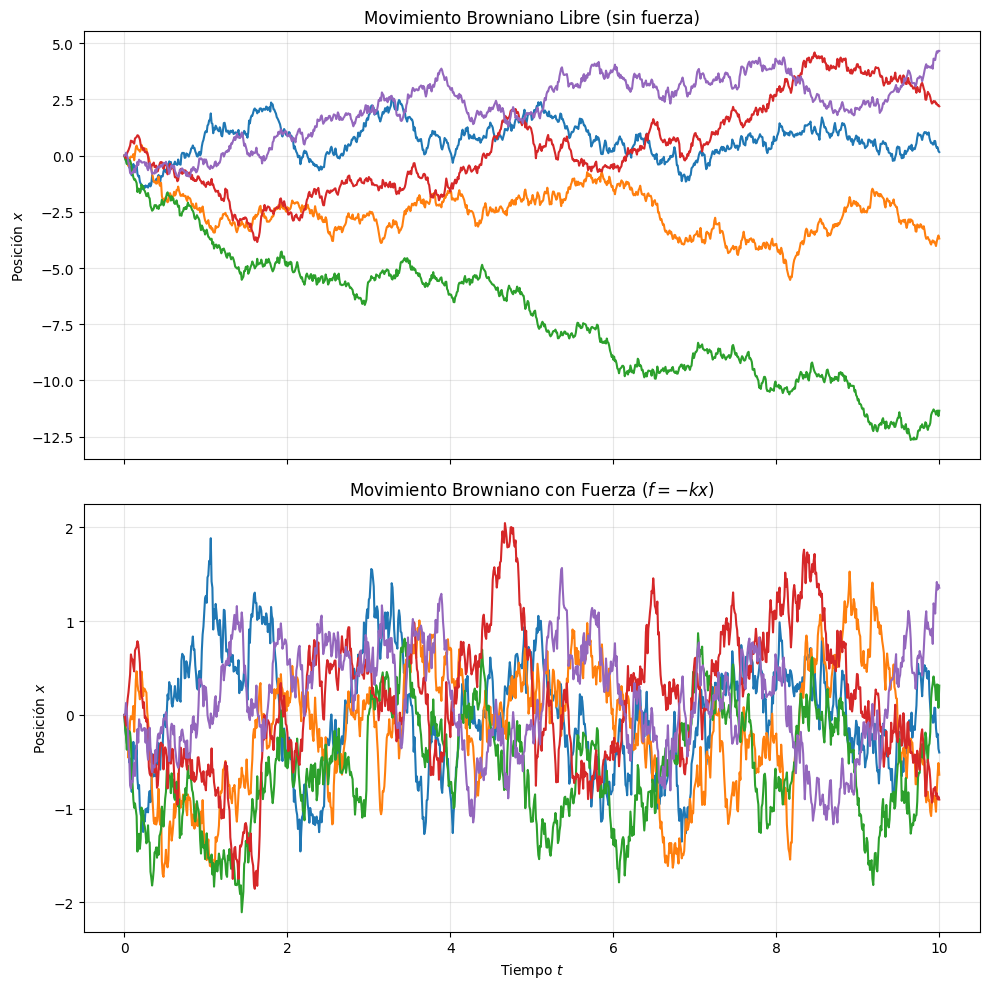

In [2]:
# Parámetros de la simulación
n_pasos = 1000
dt = 0.01
t = np.arange(n_pasos + 1) * dt
n_trayectorias = 5

D = 1.0        # Coeficiente de difusión
k_gamma = 2.0  # Relación k/gamma para la fuerza restauradora

# Inicialización
rng = np.random.default_rng(137)
x_libre = np.zeros((n_trayectorias, n_pasos + 1))
x_fuerza = np.zeros((n_trayectorias, n_pasos + 1))

# Bucle de simulación usando Euler-Maruyama
for i in range(n_trayectorias):
    for j in range(n_pasos):
        ruido = rng.normal()
        dw = np.sqrt(2 * D * dt) * ruido

        # Dinámica sin fuerza externa (partícula libre)
        x_libre[i, j + 1] = x_libre[i, j] + dw

        # Dinámica con fuerza externa f = -kx (oscilador sobreamortiguado)
        x_fuerza[i, j + 1] = x_fuerza[i, j] - k_gamma * x_fuerza[i, j] * dt + dw

# Visualización de los resultados
fig, (ax_1, ax_2) = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

for i in range(n_trayectorias):
    ax_1.plot(t, x_libre[i])
    ax_2.plot(t, x_fuerza[i])

ax_1.set_title("Movimiento Browniano Libre (sin fuerza)")
ax_1.set_ylabel("Posición $x$")
ax_1.grid(alpha=0.3)

ax_2.set_title(r"Movimiento Browniano con Fuerza $(f = -kx)$")
ax_2.set_xlabel(r"Tiempo $t$")
ax_2.set_ylabel(r"Posición $x$")
ax_2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Con modelos tipo Score

# Dinámica de Langevin con un campo score

Para una densidad de probabilidad $p_\theta(\mathbf{x})$,
definimos el campo score como

$$
\mathbf{s}_\theta(\mathbf{x})
=
\nabla_{\mathbf{x}}\log p_\theta(\mathbf{x}).
$$

Este campo apunta hacia la dirección de máximo crecimiento
local del logaritmo de la densidad.

## Relación entre el score y la fuerza

Para una distribución de Boltzmann,

$$
p_\theta(\mathbf{x})
=
\frac{1}{Z_\theta}
\exp\left[-\frac{U_\theta(\mathbf{x})}{k_BT}\right],
$$

el score es

$$
\mathbf{s}_\theta(\mathbf{x})
=
-\frac{1}{k_BT}\nabla_{\mathbf{x}}U_\theta(\mathbf{x}).
$$

Como la fuerza es $\mathbf{F}_\theta=-\nabla U_\theta$,

$$
\mathbf{F}_\theta(\mathbf{x})
=
k_BT\,\mathbf{s}_\theta(\mathbf{x}).
$$

## Ecuación estocástica

La dinámica sobreamortiguada es

$$
d\mathbf{X}_t
=
\frac{\mathbf{F}_\theta(\mathbf{X}_t)}{\gamma}\,dt
+
\sqrt{2D}\,d\mathbf{W}_t,
\qquad
D=\frac{k_BT}{\gamma}.
$$

Sustituyendo la fuerza por su expresión en términos del score:

$$
d\mathbf{X}_t
=
D\,\mathbf{s}_\theta(\mathbf{X}_t)\,dt
+
\sqrt{2D}\,d\mathbf{W}_t.
$$

El campo produce un desplazamiento dirigido y el ruido
mantiene las fluctuaciones. Durante esta evolución,
$\theta$ permanece fijo.

## Incrementos de Wiener

En $d$ dimensiones,

$$
\Delta\mathbf{W}_n
=
\sqrt{\Delta t}\,\boldsymbol{\epsilon}_n,
\qquad
\boldsymbol{\epsilon}_n\sim\mathcal{N}(\mathbf{0},I_d),
$$

con nuevos vectores independientes en cada paso.

## Actualización numérica

La aproximación de Euler–Maruyama es

$$
\mathbf{X}_{n+1}
=
\mathbf{X}_n
+
D\,\mathbf{s}_\theta(\mathbf{X}_n)\Delta t
+
\sqrt{2D\Delta t}\,\boldsymbol{\epsilon}_n.
$$

En unidades donde $D=1$:

$$
\mathbf{X}_{n+1}
=
\mathbf{X}_n
+
\mathbf{s}_\theta(\mathbf{X}_n)\Delta t
+
\sqrt{2\Delta t}\,\boldsymbol{\epsilon}_n.
$$

Con el score exacto y condiciones adecuadas de convergencia,
la dinámica continua reproduce $p_\theta$ a tiempos largos.
La actualización numérica introduce un error de discretización.

## Ejemplo: distribución gaussiana

Para una gaussiana con media $\boldsymbol{\mu}$ y
covarianza $vI_d$,

$$
\mathbf{s}(\mathbf{x})
=
-\frac{\mathbf{x}-\boldsymbol{\mu}}{v}.
$$



shape x: (200, 1001)


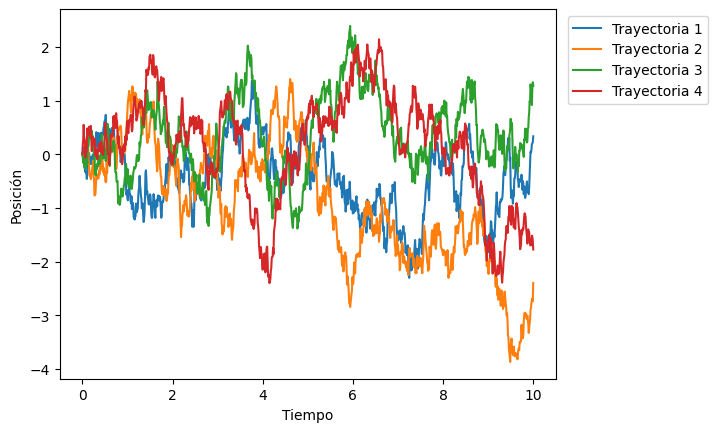

Media de las muestras:     -0.009151
Varianza de las muestras:  +0.9434
Varianza teórica discreta: +1.005


In [3]:
# Gaussiana objetivo
mu = 0.0
varianza = 1.0

def densidad(x, mu=mu, varianza=varianza):
  g = np.exp(-(x - mu)**2 / (2 * varianza))
  n = np.sqrt(2*np.pi*varianza)
  return g/n

def score(x, mu=mu, varianza=varianza):
  return -(x-mu) / varianza
rng = np.random.default_rng(42)

n_trayectorias = 200
n_pasos = 1_000
dt = 0.01

# Todas las trayectorias comienzan en la misma posición
t = np.arange(n_pasos+1 ) * dt
# x = np.zeros((n_trayectorias, n_pasos))
x = np.zeros((n_trayectorias, n_pasos + 1))
print("shape x:", np.shape(x))

# Todas las trayectorias comienzan en cero
x[:, 0] = 0.0

for k in range(n_trayectorias):
    for j in range(n_pasos):
        ruido = rng.normal()
        x[k, j + 1] = (
            x[k, j]
            + dt * score(x[k, j])
            + np.sqrt(2 * dt) * ruido
        )

for i in range(4):
  plt.plot(t, x[i], label=f"Trayectoria {i+1}")
plt.xlabel("Tiempo")
plt.ylabel("Posición")
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()
plt.close()

x=np.concat(x)
# Varianza estacionaria de la actualización discreta
varianza_discreta = varianza / (1 - dt / (2 * varianza))

# Resultados
print(f"Media de las muestras:     {np.mean(x):+.4g}")
print(f"Varianza de las muestras:  {np.var(x):+.4g}")
print(f"Varianza teórica discreta: {varianza_discreta:+.4g}")

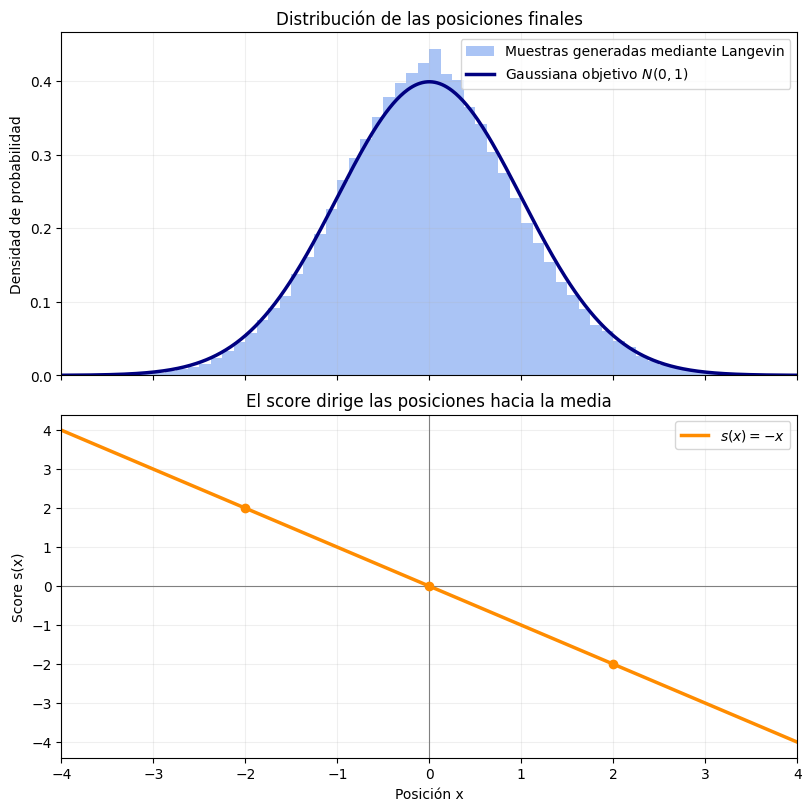

In [4]:
# Gráficas
eje = np.linspace(-4, 4, 600)

fig, (ax_1, ax_2) = plt.subplots(
    2, 1, figsize=(8, 8), constrained_layout=True, sharex=True
)

# Densidad objetivo e histograma de posiciones finales
ax_1.hist(
    x,
    bins=np.linspace(-4, 4, 65),
    density=True,
    color="cornflowerblue",
    alpha=0.55,
    label="Muestras generadas mediante Langevin"
)

ax_1.plot(
    eje,
    densidad(eje),
    color="navy",
    linewidth=2.5,
    label=r"Gaussiana objetivo ${N}(0,1)$"
)

ax_1.set(
    title="Distribución de las posiciones finales",
    ylabel="Densidad de probabilidad",
    xlim=(-4, 4)
)
ax_1.legend()
ax_1.grid(alpha=0.2)

# Campo score
ax_2.plot(
    eje,
    score(eje),
    color="darkorange",
    linewidth=2.5,
    label=r"$s(x) = -x$"
)

ax_2.axhline(0, color="gray", linewidth=0.8)
ax_2.axvline(mu, color="gray", linewidth=0.8)

ax_2.scatter(
    [-2, 0, 2],
    score(np.array([-2, 0, 2])),
    color="darkorange",
    zorder=3
)

ax_2.set(
    title="El score dirige las posiciones hacia la media",
    xlabel="Posición x",
    ylabel="Score s(x)",
    xlim=(-4, 4)
)
ax_2.legend()
ax_2.grid(alpha=0.2)

plt.show()

Simule la dinámica de Langevin de partículas inicialmente distribuidas al azar en el plano, utilizando el campo score de una gaussiana de media \((0,0)\) y covarianza identidad. Visualice el campo y cinco trayectorias. Compare la distribución final de las partículas con la gaussiana objetivo y calcule su media y covarianza.

Media final: [-0.02954483  0.01234025]
Covarianza final:
[[1.0674453  0.00384097]
 [0.00384097 1.09561538]]


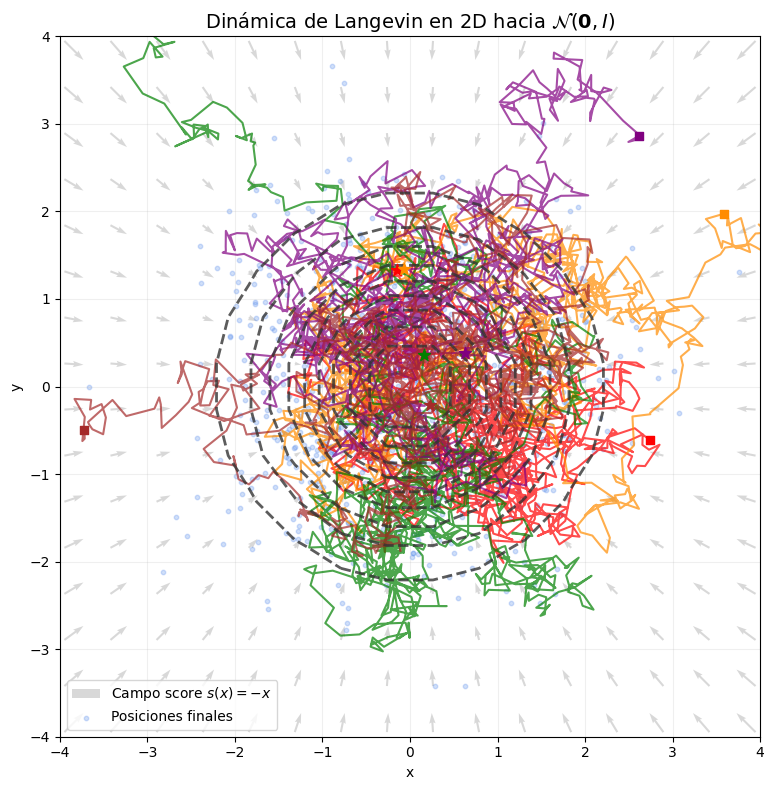

In [5]:
# Parámetros de simulación
n_particulas = 1000
n_pasos = 1000
dt = 0.01

rng = np.random.default_rng(42)

# Inicialización aleatoria en el plano (uniforme en [-5, 5] x [-5, 5])
X = rng.uniform(-5, 5, size=(n_particulas, 2))

# Guardar las primeras 5 trayectorias para visualización
trayectorias = np.zeros((5, n_pasos + 1, 2))
trayectorias[:, 0, :] = X[:5]

# Simulación de Euler-Maruyama 2D
for j in range(n_pasos):
    # El campo score de N(0, I) es s(x) = -x
    score = -X
    ruido = rng.normal(size=(n_particulas, 2))

    # Actualización de Langevin
    X = X + score * dt + np.sqrt(2 * dt) * ruido

    # Guardar estado para las trayectorias
    trayectorias[:, j + 1, :] = X[:5]

# Resultados estadísticos finales
media_final = np.mean(X, axis=0)
cov_final = np.cov(X, rowvar=False)

print(f"Media final: {media_final}")
print(f"Covarianza final:\n{cov_final}")

# Visualización
fig, ax = plt.subplots(figsize=(8, 8))

# Campo score (Quiver)
grid_x, grid_y = np.meshgrid(np.linspace(-5, 5, 20), np.linspace(-5, 5, 20))
score_x = -grid_x
score_y = -grid_y
ax.quiver(grid_x, grid_y, score_x, score_y, alpha=0.3, color='gray', label=r'Campo score $s(x)=-x$')

# Distribución final (scatter)
ax.scatter(X[:, 0], X[:, 1], alpha=0.3, s=10, color='cornflowerblue', label='Posiciones finales')

# Cinco trayectorias
colores = ['red', 'darkorange', 'green', 'purple', 'brown']
for i in range(5):
    ax.plot(trayectorias[i, :, 0], trayectorias[i, :, 1], color=colores[i], linewidth=1.5, alpha=0.7)
    # Marcar inicio (cuadrado) y fin (estrella)
    ax.scatter(trayectorias[i, 0, 0], trayectorias[i, 0, 1], color=colores[i], marker='s', s=40, zorder=5)
    ax.scatter(trayectorias[i, -1, 0], trayectorias[i, -1, 1], color=colores[i], marker='*', s=80, zorder=5)

ax.set_title(r"Dinámica de Langevin en 2D hacia $\mathcal{N}(\mathbf{0}, I)$", fontsize=14)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)
ax.set_aspect('equal')
ax.grid(alpha=0.2)

# Contornos de la Gaussiana objetivo N(0, I)
Z = np.exp(-0.5 * (grid_x**2 + grid_y**2)) / (2 * np.pi)
ax.contour(grid_x, grid_y, Z, levels=10, colors='.2',
           linestyles='--', alpha=0.8, linewidths=2)

# Arreglar la leyenda para que no duplique las trayectorias
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:3], labels[:3], loc='best')

plt.tight_layout()
plt.show()


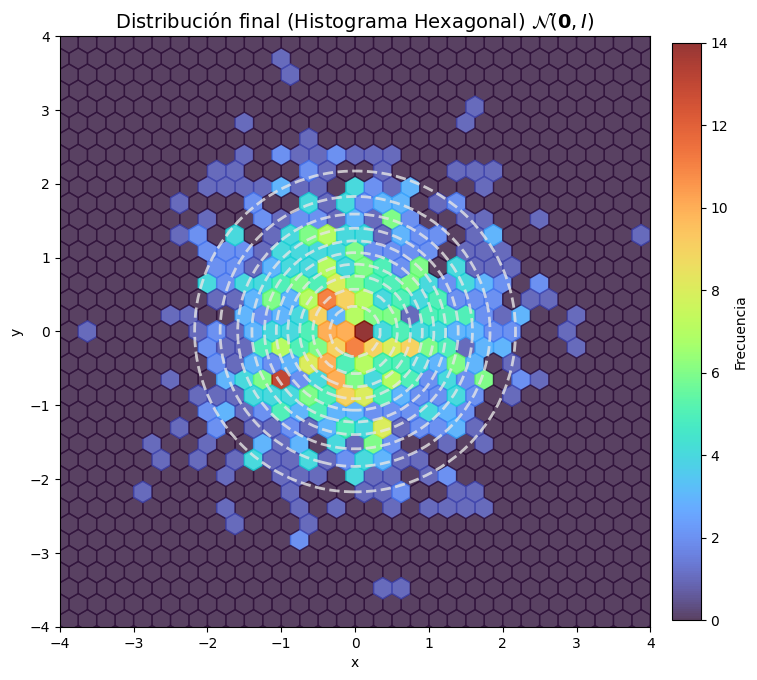

In [6]:
# Visualización con histograma 2D hexagonal
fig, ax = plt.subplots(figsize=(8, 8))

# Histograma 2D hexagonal de las posiciones finales
hb = ax.hexbin(X[:, 0], X[:, 1], gridsize=40, cmap='turbo', alpha=0.8, extent=(-5, 5, -5, 5))
fig.colorbar(hb, ax=ax,
             label='Frecuencia',
             orientation='vertical',
             pad=0.03, shrink=0.75
             )
# Contornos de la Gaussiana objetivo N(0, I)
grid_x, grid_y = np.meshgrid(np.linspace(-5, 5, 100), np.linspace(-5, 5, 100))
Z = np.exp(-0.5 * (grid_x**2 + grid_y**2)) / (2 * np.pi)
ax.contour(grid_x, grid_y, Z, levels=10, colors='.9',
           linestyles='--', alpha=0.8, linewidths=2)

ax.set_title(r"Distribución final (Histograma Hexagonal) $\mathcal{N}(\mathbf{0}, I)$", fontsize=14)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)
ax.set_aspect('equal')
ax.grid(False)

# Leyenda personalizada
from matplotlib.lines import Line2D
custom_lines = [Line2D([0], [0], color='1', lw=1.5)]

plt.tight_layout()
plt.show()